In [2]:
import numpy as np 
from pathlib import Path 
from load_file import load_file

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\absv1230_10sec.bin")

samples = load_file(file_path)

print("Number of complex samples:", len(samples))
print("Recording duration:", len(samples) / 2048000, "seconds")
print(samples.shape)
print("First 10 samples:")
print(samples[:10])

Number of complex samples: 20480000
Recording duration: 10.0 seconds
(20480000,)
First 10 samples:
[ -8.-33.j -50.-33.j -11. +1.j -11.+41.j  43.-16.j -16.-71.j -46.+17.j
  24.+99.j  10.+94.j -22.+70.j]


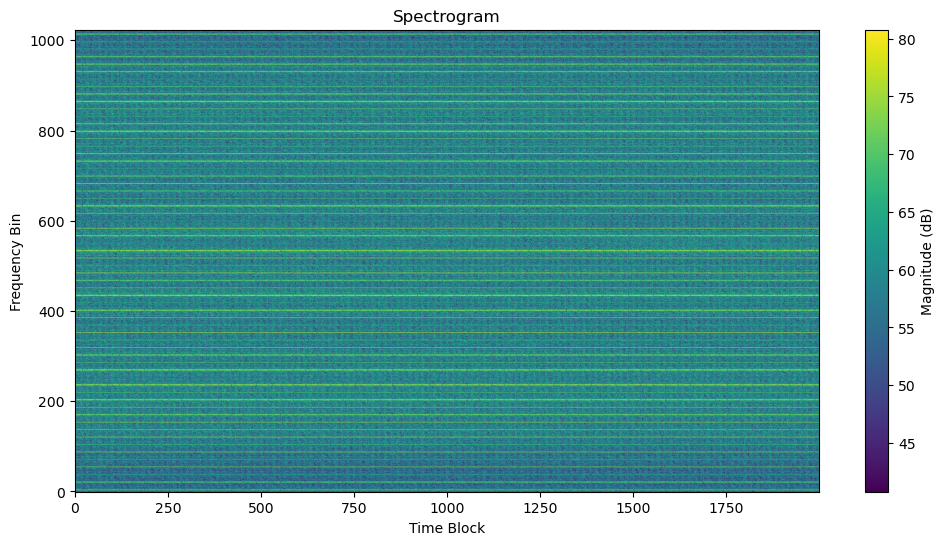

(1024, 2000)


In [8]:
from msg import msg
import matplotlib.pyplot as plt 

sample_rate = 2_048_000

spectrum_1sec = msg(samples, 1, 1024, 2000)

print(spectrum_1sec.shape)


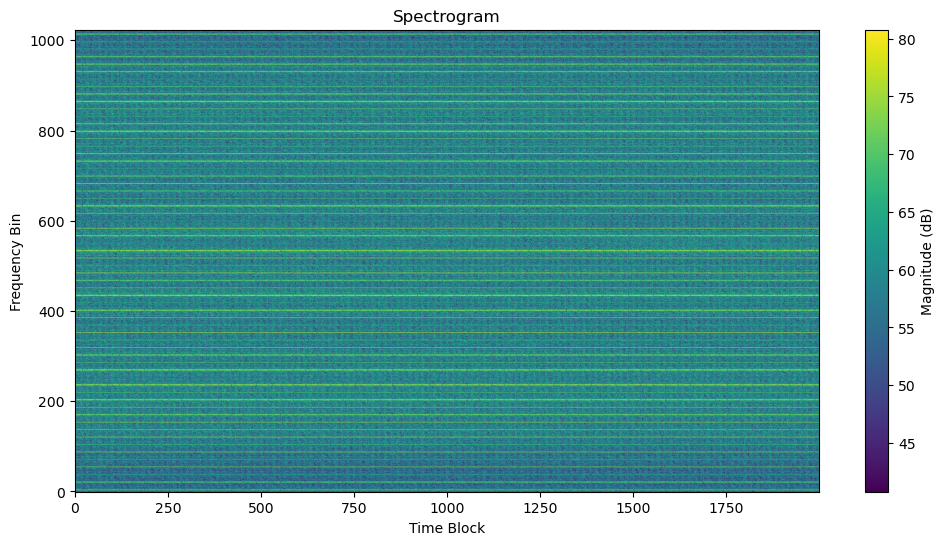

(1024, 2000)


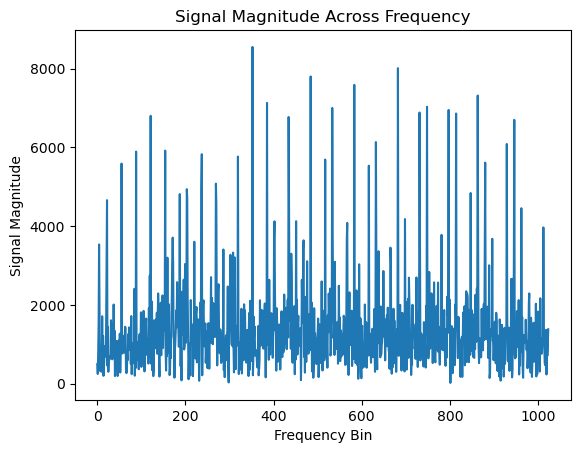

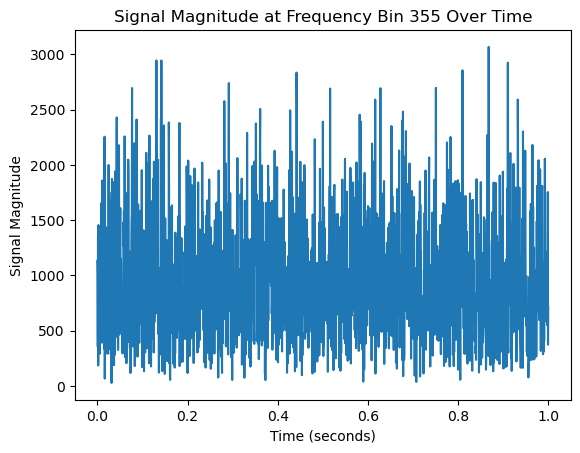

In [11]:
from msg import msg
import matplotlib.pyplot as plt 

sample_rate = 2_048_000

spectrum_1sec = msg(samples, 1, 1024, 2000)

print(spectrum_1sec.shape)

# Frequency view
plt.plot(np.abs(spectrum_1sec[:, 999]))
plt.xlabel("Frequency Bin")
plt.ylabel("Signal Magnitude")
plt.title("Signal Magnitude Across Frequency")
plt.show()

# Time axis
time = np.arange(2000) * (1024 / sample_rate)

# Time view
plt.plot(time, np.abs(spectrum_1sec[356, :]))
plt.xlabel("Time (seconds)")
plt.ylabel("Signal Magnitude")
plt.title("Signal Magnitude at Frequency Bin 355 Over Time")
plt.show()

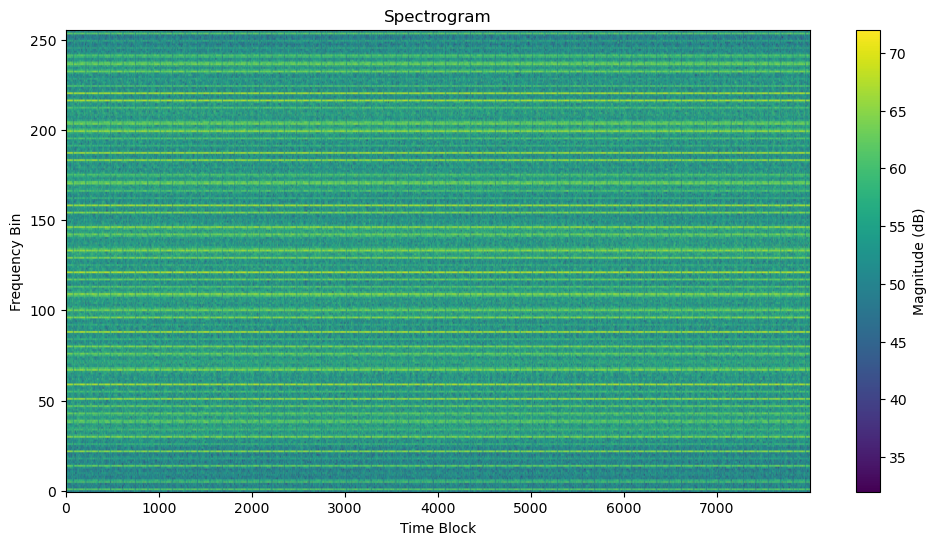

(256, 8000)


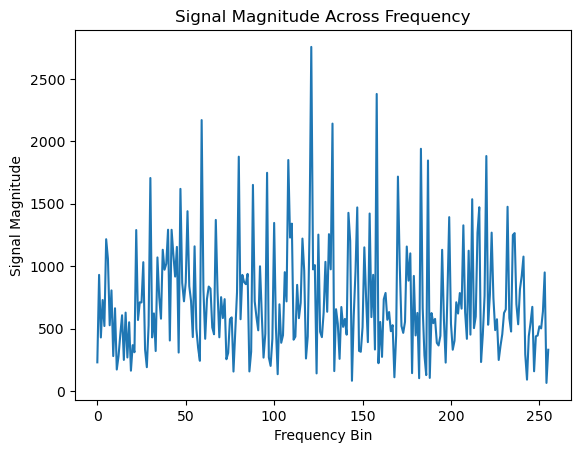

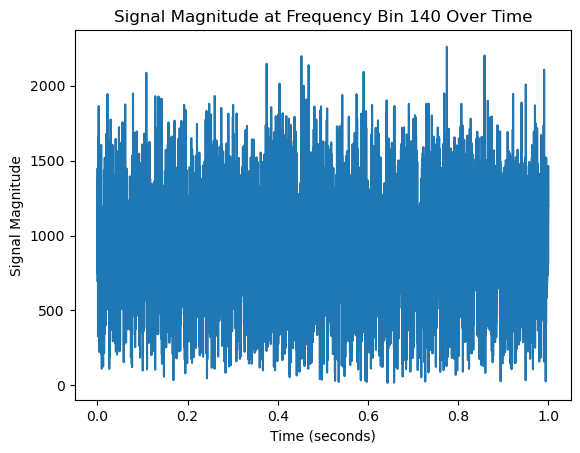

In [13]:
from msg import msg
import matplotlib.pyplot as plt 

sample_rate = 2_048_000

spectrum_1sec = msg(samples, 1, 256, 8000)

print(spectrum_1sec.shape)

# Frequency view
plt.plot(np.abs(spectrum_1sec[:, 999]))
plt.xlabel("Frequency Bin")
plt.ylabel("Signal Magnitude")
plt.title("Signal Magnitude Across Frequency")
plt.show()

# Time axis
time = np.arange(8000) * (256 / sample_rate)

# Time view
plt.plot(time, np.abs(spectrum_1sec[141, :]))
plt.xlabel("Time (seconds)")
plt.ylabel("Signal Magnitude")
plt.title("Signal Magnitude at Frequency Bin 140 Over Time")
plt.show()

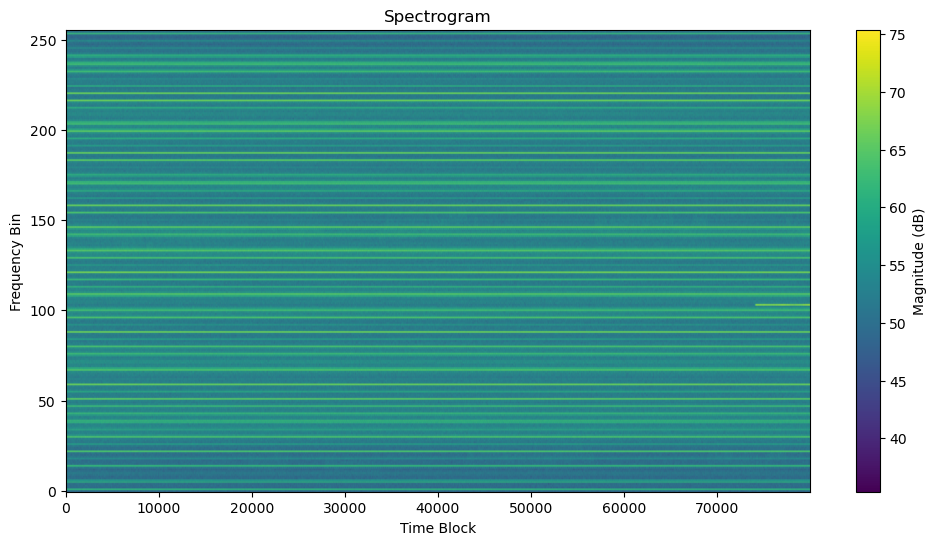

In [15]:
import numpy as np
import sounddevice as sd

spectrum_10sec = msg(samples, 1, 256, 80000)

# Select the frequency row containing the signal
audio = np.abs(spectrum_10sec[128, :])

# Scale maximum amplitude to 1
audio = audio / np.max(audio)

# Play audio at 8000 Hz
sd.play(audio, 8000)
sd.wait()